# Guía 3: procedencia, EDA y calidad de sEMG
**Benjamin Guzman Miranda** · Universidad de Santiago de Chile · PDSB 92028

Objetivo: inspeccionar un registro crudo real, preservar el original y justificar decisiones de calidad. El análisis desarrolla una base de procesamiento para control mioeléctrico futuro. La matriz tactosensible de la tesis mide otra variable y requiere validación propia.

Fuente: [Mendeley Data, versión 2](https://data.mendeley.com/datasets/ckwc76xr2z/2), Ozdemir et al. Licencia CC BY 4.0. `senal_emg.csv` coincide exactamente, en todas sus muestras, con `sEMG-dataset/raw/csv/1_raw.csv` y la matriz `data` de `1_raw.mat`. El cotejo está documentado en `evidencias/procedencia_verificada.json`. Los metadatos MAT confirman participante 1, 2.000 Hz, cuatro canales, mV e inicio 0. Los nombres originales son EMG_Raw_CH1 a EMG_RAW_CH4. No se asignan músculos a columnas sin comprobación adicional.

Ejecute este notebook desde el inicio, y después `02_caracteristicas.ipynb`. Se admiten el directorio raíz del proyecto y `notebooks/` como directorio de ejecución. Los detalles de implementación están en `src/procesamiento.py`.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / "src/procesamiento.py").is_file())
sys.path.insert(0, str(ROOT / "src"))
from procesamiento import FS, load_data, eda, characteristics, temporal_and_validation
print("Directorio del proyecto:", ROOT.name)


Directorio del proyecto: PDSB_Guia3


In [2]:
proveniencia=json.loads((ROOT/'evidencias/procedencia_verificada.json').read_text(encoding='utf-8'))
print(json.dumps(proveniencia,ensure_ascii=False,indent=2))
datos=load_data(ROOT)
original=datos.copy(deep=True)
display(datos.head())
datos.info()
print('Tipos:',datos.dtypes.to_dict())
print('Faltantes:',datos.isna().sum().to_dict())


{
  "csv_original": "ckwc76xr2z-2/sEMG-dataset/raw/csv/1_raw.csv",
  "mat_original": "ckwc76xr2z-2/sEMG-dataset/raw/mat/1_raw.mat",
  "max_abs_diff_csv": 0.0,
  "csv_shape": [
    1280000,
    4
  ],
  "sha256_csv_trabajo": "f0ab451b295030d2207ef75d1cb8d0079edc06597ceb34c61137ba025091791b",
  "sha256_mat": "14b60fb5d2ed5d2863e3e22b87b15d82b2f101534854839bce087e1e6bc33e33",
  "metadatos_mat": {
    "fs": 2000,
    "iD": 1,
    "isi": 0.5,
    "isi_units": "ms",
    "labels": [
      "EMG_Raw_CH1",
      "EMG_RAW_CH2",
      "EMG_RAW_CH3",
      "EMG_RAW_CH4"
    ],
    "start_sample": 0,
    "units": [
      "mV",
      "mV",
      "mV",
      "mV"
    ]
  }
}


,Canal_1,Canal_2,Canal_3,Canal_4
0,8.458862,-4.467468,7.217712,0.019226
1,8.465576,-4.466553,7.217102,0.019531
2,8.467407,-4.466553,7.214050,0.020447
3,8.469238,-4.464722,7.217407,0.021973
4,8.464355,-4.467773,7.214966,0.018616


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1280000 entries, 0 to 1279999
Data columns (total 4 columns):
 #   Column   Non-Null Count    Dtype  
---  ------   --------------    -----  
 0   Canal_1  1280000 non-null  float64
 1   Canal_2  1280000 non-null  float64
 2   Canal_3  1280000 non-null  float64
 3   Canal_4  1280000 non-null  float64
dtypes: float64(4)
memory usage: 39.1 MB
Tipos: {'Canal_1': dtype('float64'), 'Canal_2': dtype('float64'), 'Canal_3': dtype('float64'), 'Canal_4': dtype('float64')}
Faltantes: {'Canal_1': 0, 'Canal_2': 0, 'Canal_3': 0, 'Canal_4': 0}


## Tiempo y decisiones de calidad
La duración de soporte es N/fs = 640 s, y la última muestra está en 639,9995 s. Se usa t[n]=n/fs. No existen timestamps independientes en el CSV: la regularidad proviene del muestreo declarado y no prueba que no hubo pérdidas antes de exportar. Filas idénticas se cuentan sin borrarlas, pues pueden ser resultado de cuantización o de una meseta.

La regla de marcado es explícita y exploratoria: valores |x| >= 9,999 mV, cercanos al rango nominal ±10 mV, y rachas de valores exactamente constantes de al menos 200 muestras (0,1 s). Los candidatos IQR se cuentan, pero no se eliminan por ser extremos. La señal cruda permanece intacta. Una ventana que intersecta la máscara se conserva con bandera y se omite del resumen de actividad; aprobar estas reglas no certifica calidad fisiológica.

El canal 4 se selecciona para análisis en profundidad porque su media está próxima a cero y no tiene rachas planas de al menos 0,1 s. Esto no demuestra que sea el mejor canal para control.

Registro: (1280000, 4) fs: 2000 Hz; duración: 640.0 s
             mean       std       min       max  nan  muestras_cerca_riel
Canal_1  7.850014  0.512513  5.043030  9.999695    0                 5398
Canal_2 -4.114299  0.374199 -6.040955 -2.558594    0                    0
Canal_3  6.322590  0.588581  5.045776  7.616577    0                    0
Canal_4 -0.000576  0.018601 -0.568542  0.375061    0                    0
Tramos planos >=0,1 s: 1 
   canal  inicio_indice  fin_indice_exclusivo  inicio_s  fin_s_exclusivo  muestras  duracion_s  valor_mV                                                                        decision                                                hipotesis
Canal_1        1066769               1072000  533.3845            536.0      5231      2.6155  9.999695 Conservar original; marcar y excluir ventanas afectadas de resumen de actividad Tramo plano; posible recorte, causa física no demostrada
El tiempo procede de metadatos; no se verifican saltos con timestam

,count,mean,std,min,5%,25%,50%,75%,95%,max,nan,no_finitos,iqr,candidatos_iqr,muestras_cerca_riel,maximo_repetido
Canal_1,1280000.0,7.850014,0.512513,5.043030,7.057190,7.578125,7.775574,8.133240,8.805542,9.999695,0,0,0.555115,50272,5398,5393
Canal_2,1280000.0,-4.114299,0.374199,-6.040955,-4.602661,-4.414673,-4.225159,-3.827209,-3.489075,-2.558594,0,0,0.587463,217,0,1
Canal_3,1280000.0,6.322590,0.588581,5.045776,5.345764,5.789795,6.358032,6.846008,7.120361,7.616577,0,0,1.056213,0,0,1
Canal_4,1280000.0,-0.000576,0.018601,-0.568542,-0.016785,-0.004578,-0.000610,0.003052,0.017395,0.375061,0,0,0.007629,147218,0,1


,canal,inicio_indice,fin_indice_exclusivo,inicio_s,fin_s_exclusivo,muestras,duracion_s,valor_mV,decision,hipotesis
0,Canal_1,1066769,1072000,533.3845,536.0,5231,2.6155,9.999695,Conservar original; marcar y excluir ventanas ...,"Tramo plano; posible recorte, causa física no ..."


{
  "muestras_por_canal": 1280000,
  "canales": 4,
  "fs_documentada_Hz": 2000,
  "Ts_s": 0.0005,
  "duracion_soporte_s": 640.0,
  "tiempo_ultima_muestra_s": 639.9995,
  "marcas_tiempo_observadas": false,
  "filas_completas_duplicadas": 13,
  "discontinuidades_adquisicion": "No verificables: no hay timestamps independientes",
  "uniformidad": "Documentada en metadatos; eje t=n/fs construido, no medido",
  "regla_tramo_plano": "Valores exactamente iguales durante al menos 200 muestras (0.1 s)",
  "regla_riel": "abs(x)>=9.999 mV; umbral exploratorio cercano al rango +/-10 mV",
  "rango_nominal_mV": [
    -10,
    10
  ],
  "canal_principal": "Canal_4",
  "criterio_canal": "Media próxima a cero y ausencia de tramos planos >=0.1s; no representa superioridad fisiológica"
}


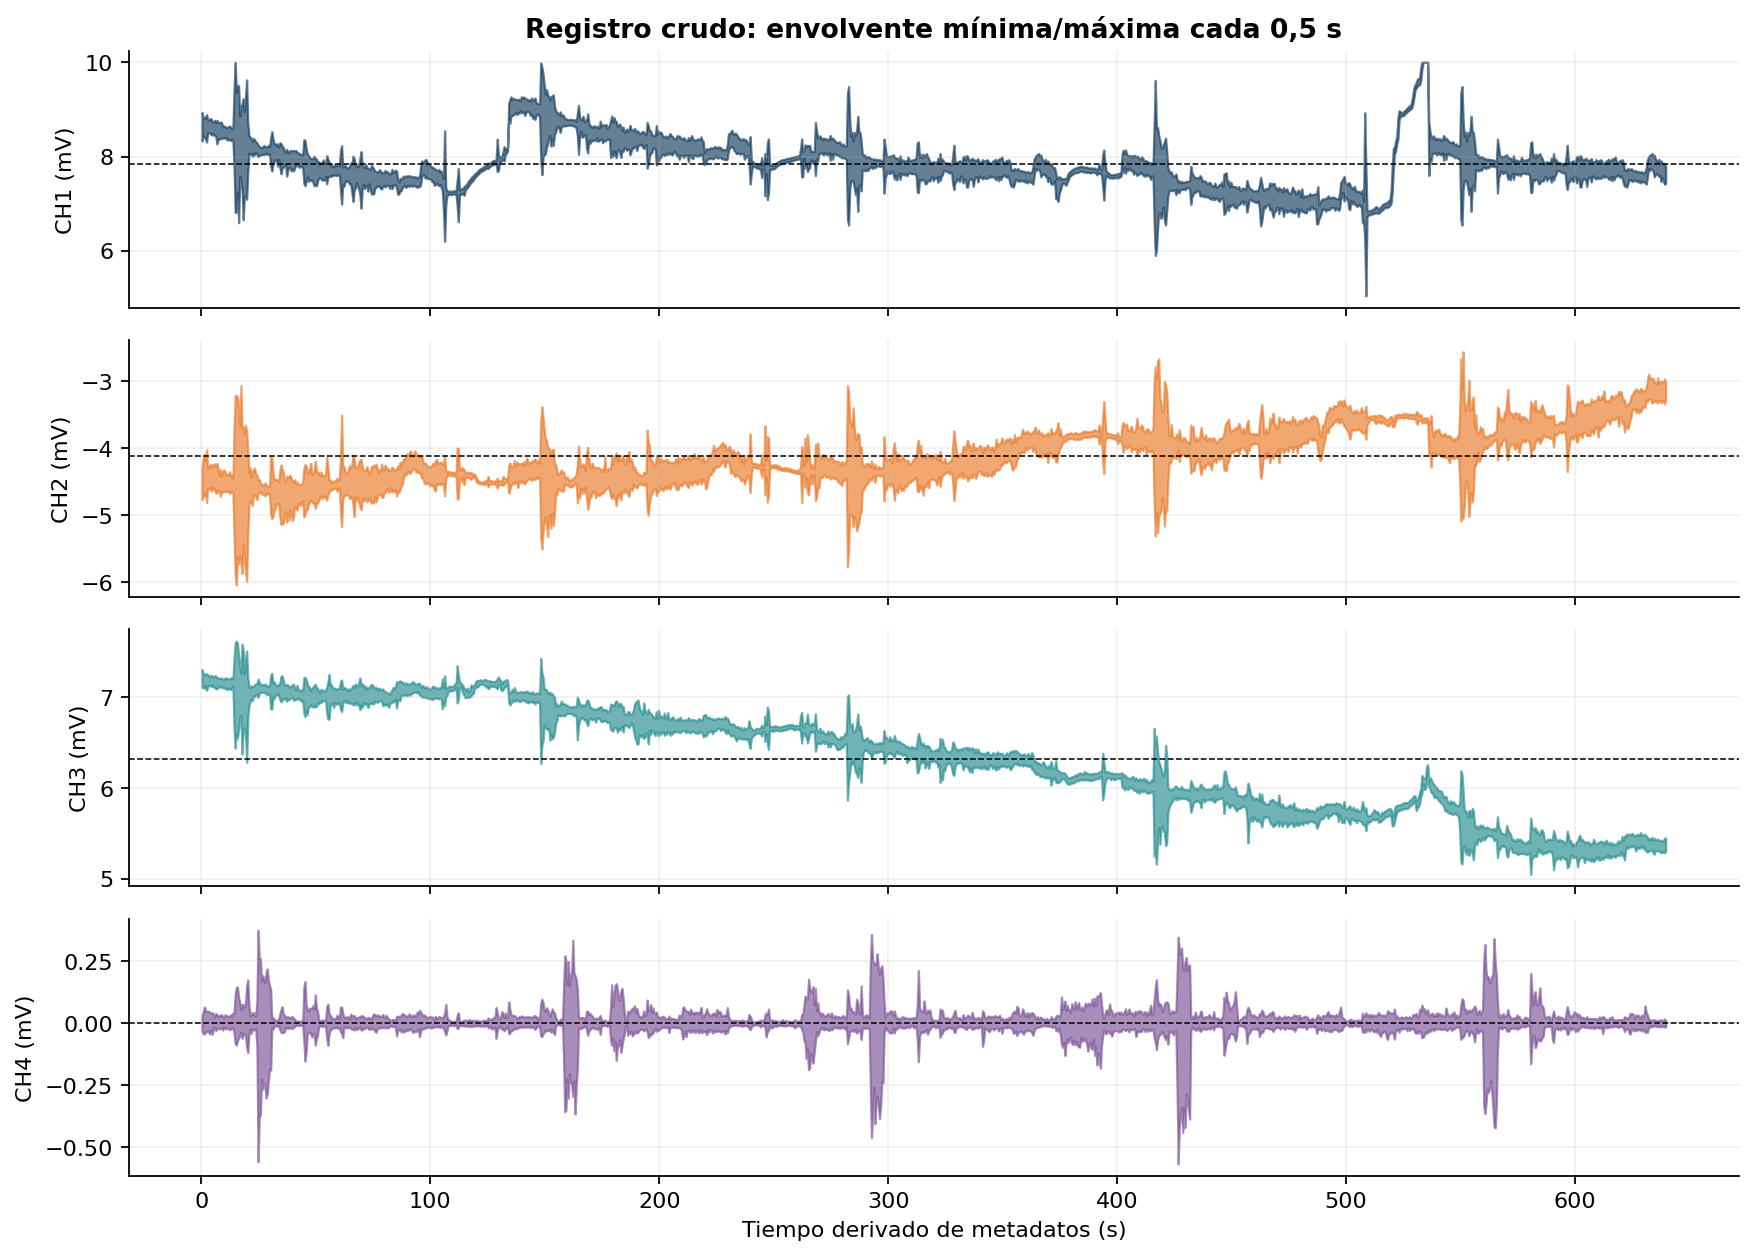

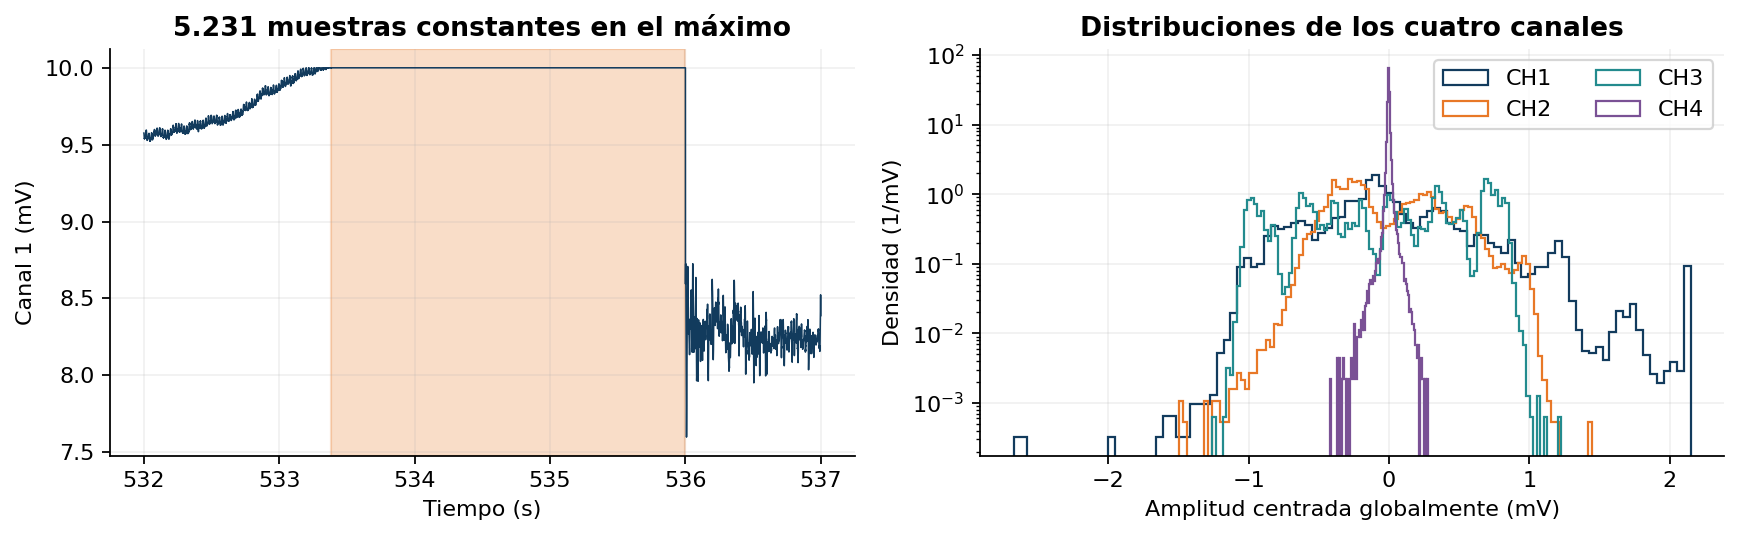

In [3]:
resumen=eda(ROOT)
display(resumen)
display(pd.read_csv(ROOT/'evidencias/anomalias.csv'))
print((ROOT/'evidencias/control_tiempo.json').read_text(encoding='utf-8'))
assert datos.equals(original), 'El original cambió'
display(Image(filename=str(ROOT/'figuras/eda_global.png')))
display(Image(filename=str(ROOT/'figuras/calidad_meseta_distribucion.png')))


## Interpretación y continuidad
El canal 1 contiene 5.231 muestras consecutivas iguales a 9,99969482421875 mV en [533,3845; 536) s. Es un indicio fuerte de recorte o de pérdida de variación en el registro, sin prueba suficiente de su causa electrónica. La ventana [534; 536) s produce RMS AC y MAV AC iguales a cero tras centrarla, lo que no identifica reposo muscular.

Restar una media cambia la referencia y no recupera un recorte. Además, el centrado global hace cero la media del registro completo, pero puede dejar una media local distinta de cero en una ventana con deriva. El centrado por ventana usado en el siguiente notebook define otras características y se declara por separado.

No se imputan muestras ni se eliminan intervalos del archivo original. El diccionario, los controles y las anomalías quedan en `datos/diccionario.csv` y `evidencias/`. El siguiente notebook agrega características, protocolo nominal, operación temporal y validación sintética.